In [39]:
#import Liabraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


In [40]:
#Load the dataset
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/project 9/all_upwork_jobs_2024-02-07-2024-03-24 (1).xlsx'
df = pd.read_excel(file_path)
print("Data loaded successfully. Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data loaded successfully. Shape: (244828, 8)


In [41]:
display(df.head())

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [42]:
#understand the dataset
print ("DATASET Dimentions:")
print ("Rows:",df.shape)
print ("\n Columns Names:",df.columns.tolist())
print ("\nDataset Information:",df.info())
print ("\nStatistical Summary:",df.describe(include="all").T)

DATASET Dimentions:
Rows: (244828, 8)

 Columns Names: ['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244818 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB

Dataset Information: None

Statistical Summary:                    count  unique  \
title             244818  205461   
link              244827  244827   
published_date    244828  233640   
is_hourly         244

In [43]:
#clean the data
jobs = df.copy()
jobs.columns = jobs.columns.str.strip().str.lower()
jobs["published_date"] = pd.to_datetime(jobs["published_date"], errors="coerce", utc=True).dt.tz_convert(None)

numeric_columns = ["hourly_low", "hourly_high", "budget"]
for col in numeric_columns:
    jobs[col] = pd.to_numeric(jobs[col], errors="coerce")

jobs["title"] = jobs["title"].fillna("").astype(str).str.strip()
jobs["country"] = jobs["country"].fillna("unknown").astype(str).str.strip()
jobs = jobs[jobs["title"] != ""].copy()
jobs = jobs.drop_duplicates(subset=["link"], keep="first")
jobs["hourly_midpoint"] = jobs[["hourly_low", "hourly_high"]].mean(axis=1, skipna=False)

print("Cleaned Dataset Shape:", jobs.shape)
display(jobs.head())

Cleaned Dataset Shape: (244818, 9)


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,hourly_midpoint
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54,False,NaN,NaN,500.0,unknown,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17,False,NaN,NaN,1100.0,United States,NaN
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46,True,10.0,30.0,NaN,United States,20.0
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08,True,NaN,NaN,NaN,United States,NaN
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42,False,NaN,NaN,650.0,India,NaN


In [44]:
#check missing values
missing_values = pd.DataFrame({"Missing Count": jobs.isnull().sum(),"Missing Percentage": (jobs.isnull().mean()*100).round(2)})
display (missing_values)

,Missing Count,Missing Percentage
title,0,0.00
link,0,0.00
published_date,0,0.00
is_hourly,0,0.00
hourly_low,142397,58.16
hourly_high,146044,59.65
budget,140935,57.57
country,0,0.00
hourly_midpoint,146044,59.65


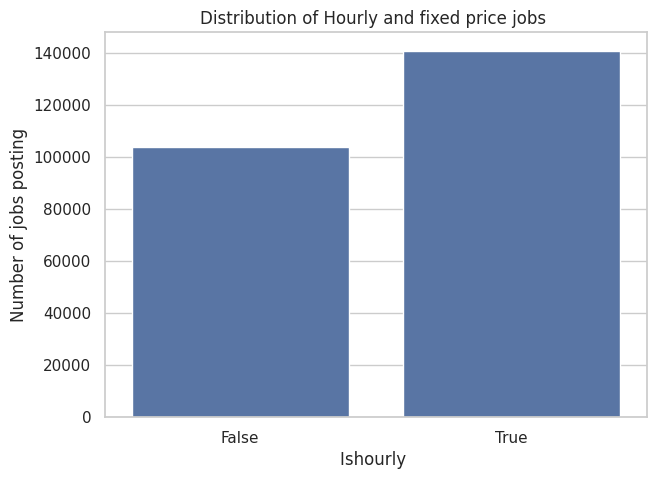

In [45]:
#understadn the distribution of job postings by contract type , country and pay
plt.figure(figsize = (7,5))
sns.countplot(data = jobs, x = "is_hourly")
plt.title ("Distribution of Hourly and fixed price jobs ")
plt.xlabel ("Ishourly ")
plt.ylabel ("Number of jobs posting")
plt.show()

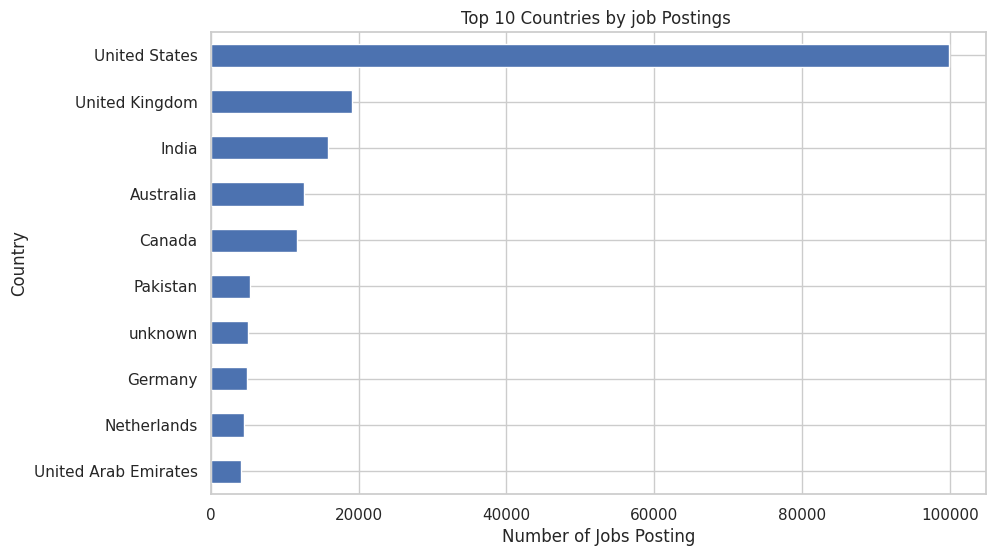

In [46]:
#top 10 countries by job posting
top_countries = (jobs [jobs["country"]!= "Unknown"]["country"].value_counts().head(10))
plt.figure(figsize=(10,6))
top_countries.sort_values().plot(kind= "barh")
plt.title ("Top 10 Countries by job Postings ")
plt.xlabel("Number of Jobs Posting")
plt.ylabel("Country")
plt.show()




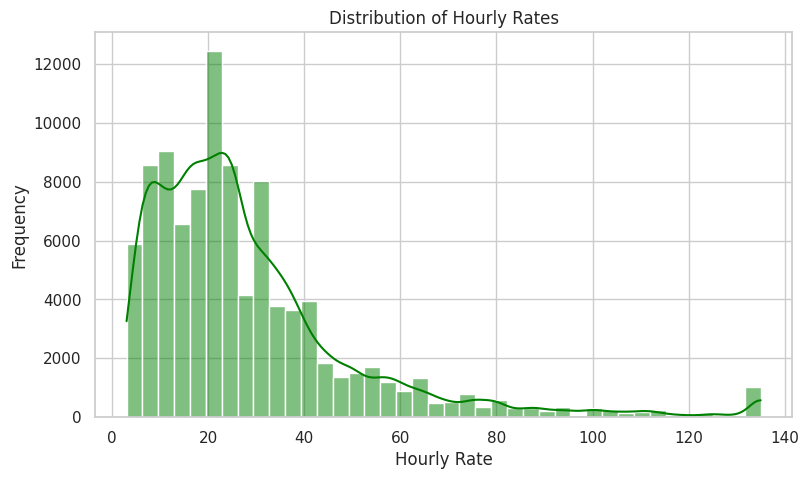

In [47]:
#distribution of hourly rates
hourly_jobs = jobs[(jobs["is_hourly"]==True) & (jobs["hourly_midpoint"].notna()) & (jobs["hourly_midpoint"]>=0)].copy()
plt.figure(figsize=(9,5))
sns.histplot(hourly_jobs["hourly_midpoint"].clip(upper=hourly_jobs["hourly_midpoint"].quantile(0.99)), bins=40, kde=True, color="green")
plt.title("Distribution of Hourly Rates")
plt.xlabel("Hourly Rate")
plt.ylabel("Frequency")
plt.show()

In [48]:
#categorise jobs using title keywords and compare their hourly pay
keyword_groups = {
    "Data Analytics": ["data analyst", "data scientist", "data engineer", "analytics", "power bi", "tableau", "sql"],
    "Software Development": ["developer", "software", "programmer","full stack", "backend", "frontend"],
    "AI and Machine Learning": ["artificial intelligence", "machine learning", "generative ai", "chatgpt", "llm"],
    "Design": ["designer", "graphic design", "illustrator","ui ux", "web design"],
    "Marketing": ["marketing", "seo", "social media","copywriter", "content marketing"],
    "Writing": [ "writer", "writing", "translation","proofreading", "editor"],
    "Admin and Support": ["virtual assistant", "customer support", "data entry", "administrative"],
    "Finance": ["accountant", "bookkeeping", "financial analyst", "quickbooks", "finance"]}

def assign_category(title):
    title = str(title).lower()
    for category, keywords in keyword_groups.items():
        if any(keyword in title for keyword in keywords):
            return category
    return "Other"
jobs["category"] = jobs["title"].apply(assign_category)
display(jobs[["title", "category"]].head(20))

,title,category
0,Experienced Media Buyer For Solar Pannel and R...,Other
1,Full Stack Developer,Software Development
2,SMMA Bubble App,Other
3,Talent Hunter Specialized in Marketing,Marketing
4,Data Engineer,Data Analytics
5,SEO for Portuguese Psychologist site,Marketing
6,Want to fix the WordPress Plugin,Other
7,need Portuguese writers who can understand and...,Writing
8,Looker Studio Dashboard for Leadgen and E-Comm...,Other
9,PHP/HTML/CSS WordPress Developer Needed for We...,Software Development


In [49]:
#calculate average and median hourly rates
hourly_jobs = jobs[(jobs["is_hourly"] == True) & (jobs["hourly_midpoint"].notna()) & (jobs["hourly_midpoint"] >= 0)].copy()
category_salary = (hourly_jobs.groupby("category").agg(Job_Count=("hourly_midpoint", "count"), Average_Hourly_Rate=("hourly_midpoint", "mean"),
Median_Hourly_Rate=("hourly_midpoint", "median") ).sort_values("Job_Count", ascending=False))
display(category_salary.round(2))

,Job_Count,Average_Hourly_Rate,Median_Hourly_Rate
category,,,
Other,62693,31.26,23.0
Marketing,8948,24.84,17.5
Software Development,8931,30.19,25.0
Writing,6295,27.67,22.5
Design,6295,27.70,25.0
Admin and Support,2753,13.91,8.0
Data Analytics,1293,36.04,30.0
Finance,1190,30.62,20.5
AI and Machine Learning,376,33.97,28.5


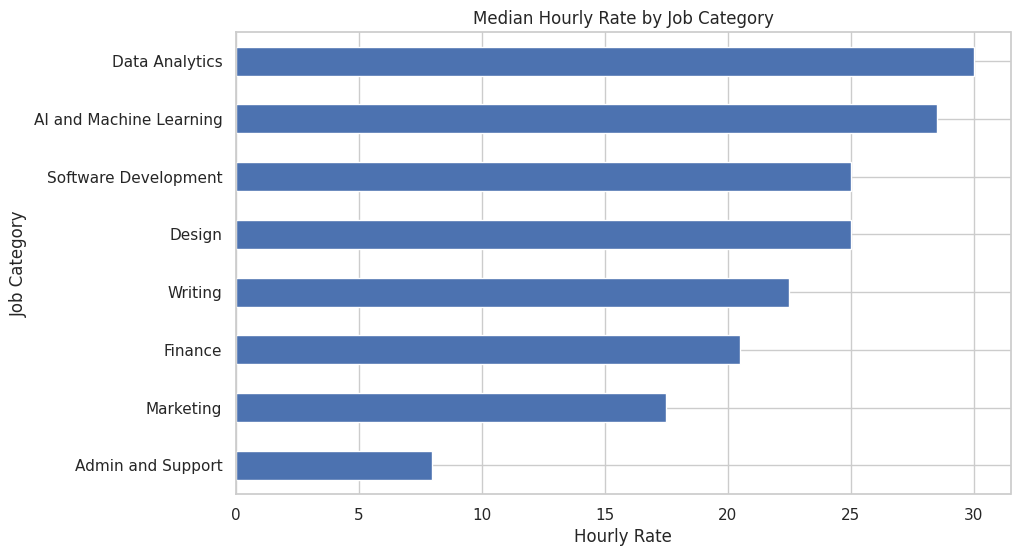

In [50]:
#visualise salary by category
salary_plot = category_salary.drop(index="Other",errors="ignore").sort_values("Median_Hourly_Rate")
plt.figure(figsize=(10, 6))
salary_plot["Median_Hourly_Rate"].plot(kind="barh")
plt.title("Median Hourly Rate by Job Category")
plt.xlabel("Hourly Rate")
plt.ylabel("Job Category")
plt.show()

In [51]:
#identify the categories with the highest posting frequency and compare posting volumes across time
category_counts = (jobs["category"].value_counts().reset_index())
category_counts.columns = ["Category", "Job_Count"]
display(category_counts)

,Category,Job_Count
0,Other,164067
1,Software Development,19011
2,Marketing,18825
3,Writing,17457
4,Design,14661
5,Admin and Support,5290
6,Data Analytics,2515
7,Finance,2069
8,AI and Machine Learning,923


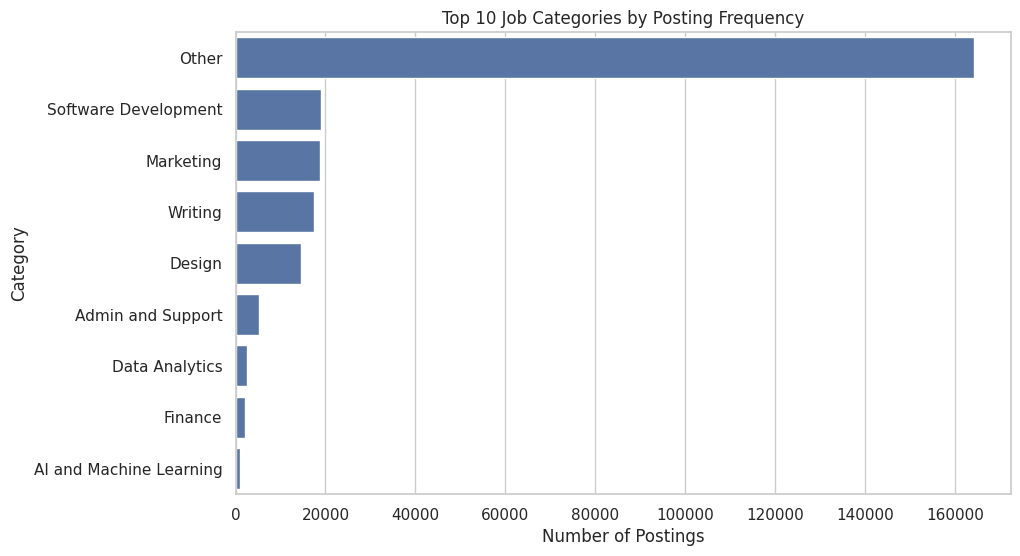

In [52]:
plt.figure(figsize=(10, 6))
sns.barplot( data=category_counts.head(10),x="Job_Count",y="Category")
plt.title("Top 10 Job Categories by Posting Frequency")
plt.xlabel("Number of Postings")
plt.ylabel("Category")
plt.show()

In [53]:
#compare the first and second halves of the datasets data range
jobs["published_date"] = pd.to_datetime(jobs["published_date"], errors="coerce")
start_date = jobs["published_date"].min()
end_date = jobs["published_date"].max()
mid_date = start_date + (end_date - start_date) / 2
jobs["Period"] = np.where(jobs["published_date"] <= mid_date,"First Half","Second Half")
growth_table = pd.crosstab(jobs["category"],jobs["Period"])
for period in ["First Half", "Second Half"]:
    if period not in growth_table.columns:
        growth_table[period] = 0
growth_table["Change"] = ( growth_table["Second Half"] - growth_table["First Half"])
growth_table["Growth_Percent"] = np.where( growth_table["First Half"] > 0, growth_table["Change"] / growth_table["First Half"] * 100,np.nan)
display(growth_table.sort_values("Change", ascending=False).round(2))

Period,First Half,Second Half,Change,Growth_Percent
category,,,,
Other,15,164052,164037,1093580.00
Software Development,2,19009,19007,950350.00
Marketing,1,18824,18823,1882300.00
Writing,3,17454,17451,581700.00
Design,1,14660,14659,1465900.00
Admin and Support,3,5287,5284,176133.33
Data Analytics,0,2515,2515,NaN
Finance,1,2068,2067,206700.00
AI and Machine Learning,0,923,923,NaN


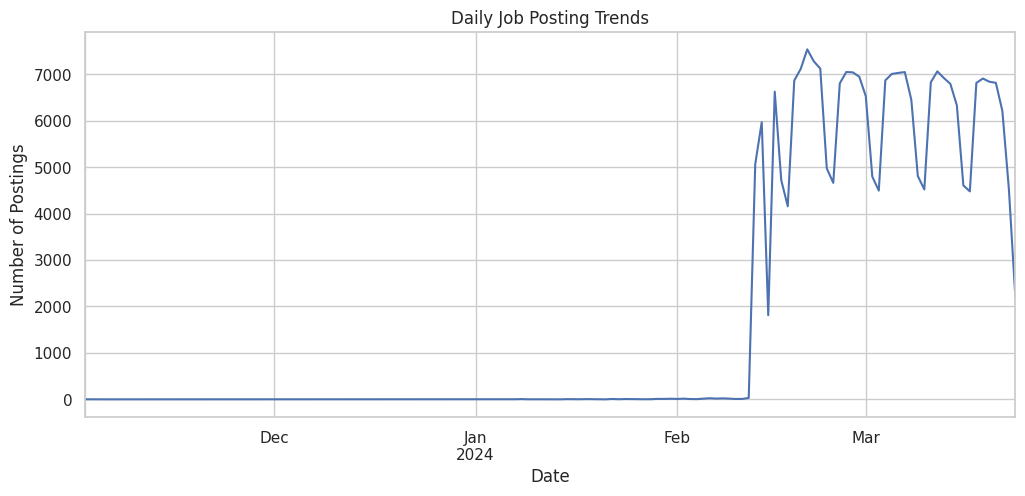

In [54]:
#analysing posting patterns over time and evaluate an exploratory forcasting model
daily_jobs = (jobs.dropna(subset=["published_date"]).set_index("published_date").resample("D") .size())
plt.figure(figsize=(12, 5))
daily_jobs.plot()
plt.title("Daily Job Posting Trends")
plt.xlabel("Date")
plt.ylabel("Number of Postings")
plt.show()

In [55]:
#create weekly posting counts by category
weekly_jobs = (jobs.dropna(subset=["published_date"]).groupby([pd.Grouper(key="published_date", freq="W"),"category"]).size().reset_index(name="Job_Count"))
display(weekly_jobs.head(20))

,published_date,category,Job_Count
0,2023-11-05,Other,1
1,2023-12-03,Writing,1
2,2023-12-10,Other,1
3,2023-12-17,Marketing,1
4,2023-12-17,Other,1
5,2023-12-17,Writing,1
6,2023-12-24,Finance,1
7,2023-12-24,Other,1
8,2023-12-31,Other,2
9,2023-12-31,Writing,1


In [56]:
#Build and evaluate a forcasting model
forecast_results = []
top_categories = ( jobs["category"].value_counts().head(5).index)
for category in top_categories:
    series = ( weekly_jobs[weekly_jobs["category"] == category].set_index("published_date")["Job_Count"].sort_index())
    if series.empty:
        continue
    series = series.asfreq("W-SUN", fill_value=0)
    model_data = pd.DataFrame({"Job_Count": series,"Lag_1": series.shift(1),"Lag_2": series.shift(2)}).dropna()
    if len(model_data) < 8:
        print( f"Skipping {category}: " "insufficient weekly observations.")
        continue
    split_index = int(len(model_data) * 0.8)
    train = model_data.iloc[:split_index]
    test = model_data.iloc[split_index:]
    if test.empty:
        continue
    X_train = train[["Lag_1", "Lag_2"]]
    y_train = train["Job_Count"]
    X_test = test[["Lag_1", "Lag_2"]]
    y_test = test["Job_Count"]
    model = RandomForestRegressor(n_estimators=200,random_state=42,min_samples_leaf=2)
    model.fit(X_train, y_train)
    predictions = np.maximum( 0, model.predict(X_test))
    mae = mean_absolute_error( y_test, predictions)
    rmse = np.sqrt(mean_squared_error( y_test, predictions))
    forecast_results.append({"Category": category,"MAE": mae, "RMSE": rmse,"Test_Weeks": len(test)})
forecast_df = pd.DataFrame(forecast_results)
display(forecast_df.round(2))

,Category,MAE,RMSE,Test_Weeks
0,Other,12677.34,12705.82,4
1,Software Development,208.17,268.14,2
2,Marketing,750.48,763.10,3
3,Writing,211.45,241.58,3
4,Design,122.29,130.31,2


In [57]:

# Exclude countries with fewer than 30 observations
country_rates = (hourly_jobs[ hourly_jobs["country"] != "Unknown"].groupby("country").agg(Job_Count=("hourly_midpoint", "count"), Average_Rate=("hourly_midpoint", "mean"), Median_Rate=("hourly_midpoint", "median")))
country_rates = country_rates[country_rates["Job_Count"] >= 30]
country_rates = country_rates.sort_values("Average_Rate", ascending=False)
display(country_rates.head(20).round(2))

,Job_Count,Average_Rate,Median_Rate
country,,,
Malaysia,325,48.10,22.5
Thailand,287,42.21,22.5
Jordan,55,36.15,22.5
United States,46619,32.58,25.0
Latvia,106,32.39,30.0
Hungary,148,32.32,25.0
Cyprus,160,31.89,25.0
Kenya,314,31.82,26.0
Bangladesh,733,31.32,20.0


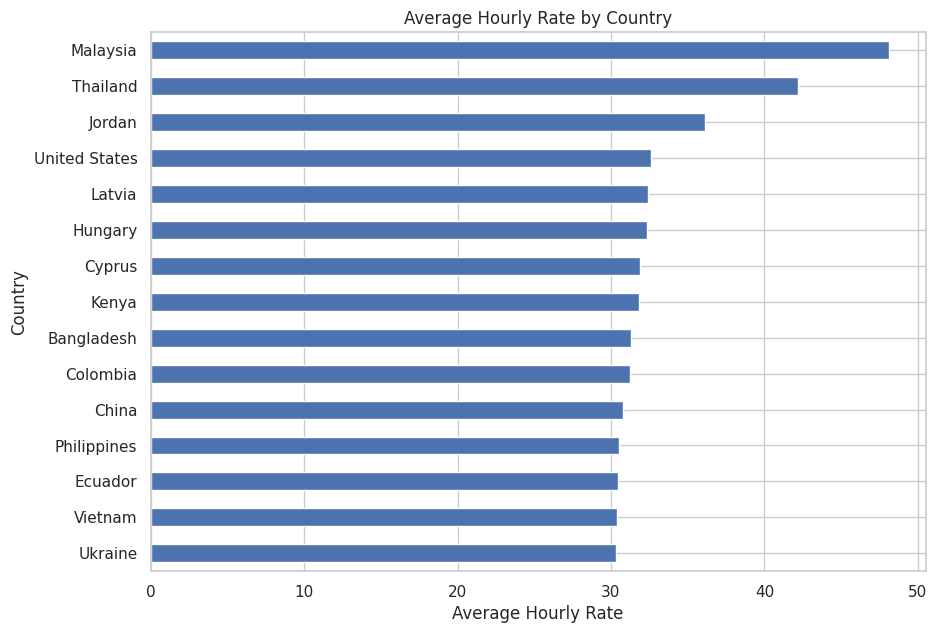

In [58]:
top_15_countries = (country_rates.head(15).sort_values("Average_Rate"))
plt.figure(figsize=(10, 7))
top_15_countries["Average_Rate"].plot(kind="barh")
plt.title("Average Hourly Rate by Country")
plt.xlabel("Average Hourly Rate")
plt.ylabel("Country")
plt.show()

In [59]:
#convert job titles in to TFIDF features
recommendation_jobs = jobs.reset_index(drop=True).copy()
recommendation_jobs["title_clean"] = (recommendation_jobs["title"].str.lower().str.replace(r"[^a-z0-9+#. ]"," ",regex=True))
tfidf = TfidfVectorizer(stop_words="english",ngram_range=(1, 2),min_df=2,max_features=50000)
title_matrix = tfidf.fit_transform( recommendation_jobs["title_clean"])
print("TF-IDF matrix shape:", title_matrix.shape)

TF-IDF matrix shape: (244818, 50000)


In [60]:
#create recommendation function
def recommend_jobs(query,top_n=10,country=None,hourly_only=False):
    query = str(query).strip()
    if not query:
        raise ValueError( "Please enter a job title or skill.")
    query_vector = tfidf.transform([query.lower()])
    similarity_scores = cosine_similarity(query_vector,title_matrix).ravel()
    results = recommendation_jobs.copy()
    results["Similarity_Score"] = similarity_scores
    if country:
        results = results[ results["country"].str.contains(re.escape(country),case=False,na=False )]
    if hourly_only:
        results = results[results["is_hourly"] == True]
    results = results.sort_values(
        "Similarity_Score", ascending=False )
    output_columns = ["title","country","is_hourly", "hourly_low","hourly_high","budget","published_date","link","Similarity_Score"]
    return results[output_columns].head(top_n)

In [61]:
#Test the recommendation engine
my_query = "Data Analyst Python SQL"
recommendations = recommend_jobs(query=my_query, top_n=10)
display(recommendations)

,title,country,is_hourly,hourly_low,hourly_high,budget,published_date,link,Similarity_Score
141310,Python and SQL Developer,United States,True,10.0,20.0,NaN,2024-03-09 00:11:58,https://www.upwork.com/jobs/Python-and-SQL-Dev...,0.648308
14084,Data Analyst - Tableau and SQL,United States,False,NaN,NaN,500.0,2024-02-17 06:54:22,https://www.upwork.com/jobs/Data-Analyst-Table...,0.611490
117824,Data Analyst,United States,True,5.0,15.0,NaN,2024-03-03 14:11:52,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
45728,Data Analyst,Italy,True,13.0,30.0,NaN,2024-02-24 19:10:53,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
53443,Data Analyst,India,True,NaN,NaN,NaN,2024-02-22 09:19:29,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
14407,Data Analyst,Egypt,True,5.0,50.0,NaN,2024-02-16 21:39:00,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
36619,Data Analyst,United Kingdom,True,20.0,60.0,NaN,2024-02-17 19:55:37,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
78710,Data Analyst,Switzerland,True,13.0,30.0,NaN,2024-02-25 07:04:22,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838
57564,Data analyst,Saudi Arabia,True,13.0,30.0,NaN,2024-02-23 08:01:52,https://www.upwork.com/jobs/Data-analyst_%7E01...,0.600838
50362,Data Analyst,United States,True,18.0,50.0,NaN,2024-02-22 09:52:26,https://www.upwork.com/jobs/Data-Analyst_%7E01...,0.600838


In [62]:
recommendations = recommend_jobs(query="Python Developer",top_n=10,country="United States",hourly_only=True)
display(recommendations)

,title,country,is_hourly,hourly_low,hourly_high,budget,published_date,link,Similarity_Score
241481,Python Developer,United States,True,NaN,NaN,NaN,2024-03-24 02:54:34,https://www.upwork.com/jobs/Python-Developer_%...,1.0
173240,Python Developer,United States,True,16.0,35.0,NaN,2024-03-14 13:44:46,https://www.upwork.com/jobs/Python-Developer_%...,1.0
84307,"Python Developer with PYPDF2, FillPdf etc",United States,True,NaN,NaN,NaN,2024-02-29 01:16:31,https://www.upwork.com/jobs/Python-Developer-w...,1.0
82995,Python and R Developer,United States,True,25.0,30.0,NaN,2024-02-26 20:31:41,https://www.upwork.com/jobs/Python-and-Develop...,1.0
154391,Python Developer,United States,True,8.0,10.0,NaN,2024-03-07 14:47:49,https://www.upwork.com/jobs/Python-Developer_%...,1.0
78461,Python Developer,United States,True,30.0,50.0,NaN,2024-02-24 14:45:55,https://www.upwork.com/jobs/Python-Developer_%...,1.0
155629,Python Developer,United States,True,15.0,30.0,NaN,2024-03-07 15:49:38,https://www.upwork.com/jobs/Python-Developer_%...,1.0
38155,Python Developer,United States,True,15.0,40.0,NaN,2024-02-17 10:25:35,https://www.upwork.com/jobs/Python-Developer_%...,1.0
132537,Python Developer,United States,True,16.0,35.0,NaN,2024-03-10 01:35:06,https://www.upwork.com/jobs/Python-Developer_%...,1.0
223284,Python Developer,United States,True,15.0,25.0,NaN,2024-03-17 15:01:26,https://www.upwork.com/jobs/Python-Developer_%...,1.0


In [63]:
jobs["Month"] = (jobs["published_date"].dt.to_period("M").astype(str))
monthly_jobs = (jobs.groupby("Month").size().reset_index(name="Job_Count"))
display(monthly_jobs)

,Month,Job_Count
0,2023-11,1
1,2023-12,10
2,2024-01,96
3,2024-02,101886
4,2024-03,142825


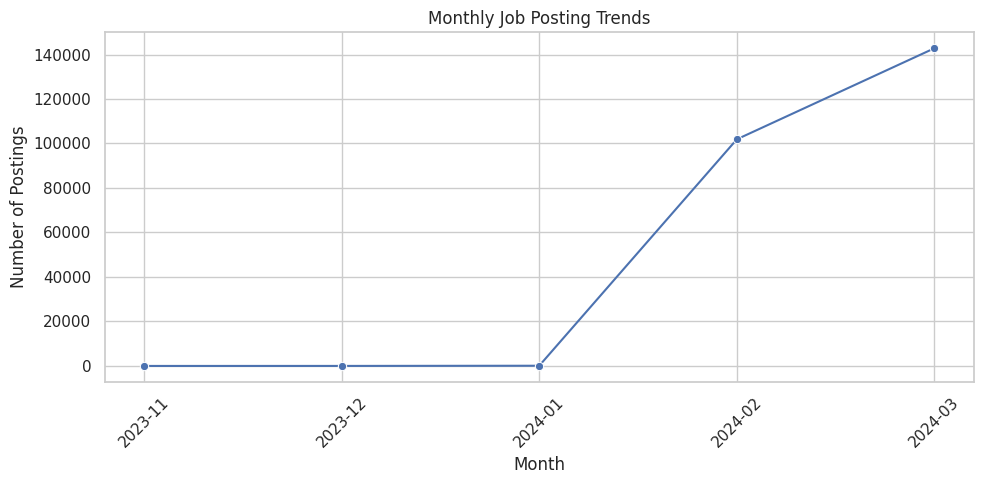

In [64]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_jobs, x="Month",y="Job_Count",marker="o")
plt.title("Monthly Job Posting Trends")
plt.xlabel("Month")
plt.ylabel("Number of Postings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [65]:
monthly_category = pd.crosstab(jobs["Month"],jobs["category"])
display(monthly_category)

category,AI and Machine Learning,Admin and Support,Data Analytics,Design,Finance,Marketing,Other,Software Development,Writing
Month,,,,,,,,,
2023-11,0,0,0,0,0,0,1,0,0
2023-12,0,0,0,0,1,1,5,0,3
2024-01,0,6,1,3,3,6,62,10,5
2024-02,371,2553,1035,6081,849,7769,67461,7786,7981
2024-03,552,2731,1479,8577,1216,11049,96538,11215,9468


In [66]:
remote_pattern = (r"\b(remote|work from home|wfh|" r"anywhere|distributed|virtual)\b")
jobs["Remote_Signal"] = (jobs["title"].str.lower().str.contains(remote_pattern,regex=True,na=False ))
remote_summary = (jobs.groupby("Month").agg(Remote_Postings=("Remote_Signal", "sum"),Total_Postings=("title", "count") ))
remote_summary["Remote_Percentage"] = (remote_summary["Remote_Postings"] /remote_summary["Total_Postings"] * 100)
display(remote_summary.round(2))

,Remote_Postings,Total_Postings,Remote_Percentage
Month,,,
2023-11,0,1,0.00
2023-12,0,10,0.00
2024-01,9,96,9.38
2024-02,2489,101886,2.44
2024-03,3207,142825,2.25


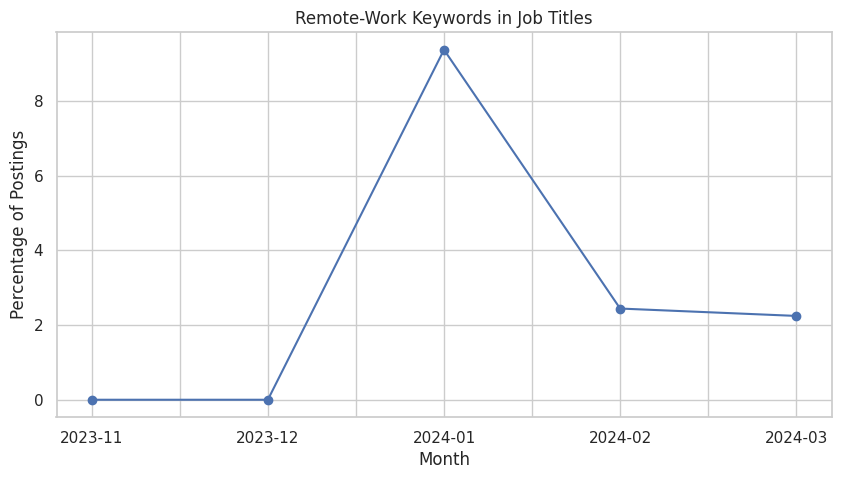

In [67]:
plt.figure(figsize=(10, 5))
remote_summary["Remote_Percentage"].plot(kind="line",marker="o")
plt.title("Remote-Work Keywords in Job Titles")
plt.xlabel("Month")
plt.ylabel("Percentage of Postings")
plt.show()

In [68]:
print("========== JOB MARKET SUMMARY ==========")
print("\n1. Most frequent job categories:")
display(category_counts.head(10))
print("\n2. Job categories with the highest median hourly rates:")
display(category_salary.sort_values( "Median_Hourly_Rate",ascending=False).head(10).round(2))
print("\n3. Countries with the highest average hourly rates:")
display(country_rates.head(10).round(2))
print("\n4. Monthly job posting counts:")
display(monthly_jobs)
print("\n5. Remote-work keyword analysis:")
display(remote_summary.round(2))
print("\n6. Forecast evaluation:")
display(forecast_df.round(2))

========== JOB MARKET SUMMARY ==========

1. Most frequent job categories:


,Category,Job_Count
0,Other,164067
1,Software Development,19011
2,Marketing,18825
3,Writing,17457
4,Design,14661
5,Admin and Support,5290
6,Data Analytics,2515
7,Finance,2069
8,AI and Machine Learning,923



2. Job categories with the highest median hourly rates:


,Job_Count,Average_Hourly_Rate,Median_Hourly_Rate
category,,,
Data Analytics,1293,36.04,30.0
AI and Machine Learning,376,33.97,28.5
Software Development,8931,30.19,25.0
Design,6295,27.70,25.0
Other,62693,31.26,23.0
Writing,6295,27.67,22.5
Finance,1190,30.62,20.5
Marketing,8948,24.84,17.5
Admin and Support,2753,13.91,8.0



3. Countries with the highest average hourly rates:


...

,Month,Job_Count
0,2023-11,1
1,2023-12,10
2,2024-01,96
3,2024-02,101886
4,2024-03,142825



5. Remote-work keyword analysis:


,Remote_Postings,Total_Postings,Remote_Percentage
Month,,,
2023-11,0,1,0.00
2023-12,0,10,0.00
2024-01,9,96,9.38
2024-02,2489,101886,2.44
2024-03,3207,142825,2.25



6. Forecast evaluation:


,Category,MAE,RMSE,Test_Weeks
0,Other,12677.34,12705.82,4
1,Software Development,208.17,268.14,2
2,Marketing,750.48,763.10,3
3,Writing,211.45,241.58,3
4,Design,122.29,130.31,2


In [69]:
import os
os.makedirs( "job_market_outputs",exist_ok=True)
category_counts.to_csv( "job_market_outputs/category_counts.csv",index=False)
category_salary.to_csv("job_market_outputs/category_salary.csv")
growth_table.to_csv( "job_market_outputs/category_growth.csv")
country_rates.to_csv( "job_market_outputs/country_hourly_rates.csv")
monthly_jobs.to_csv( "job_market_outputs/monthly_postings.csv",index=False)
remote_summary.to_csv( "job_market_outputs/remote_work_analysis.csv")
forecast_df.to_csv("job_market_outputs/forecast_evaluation.csv",index=False)
print("All CSV reports exported successfully.")

All CSV reports exported successfully.


In [70]:
with pd.ExcelWriter("Job_Market_Analysis_Results.xlsx",engine="openpyxl") as writer:
    category_counts.to_excel(writer,sheet_name="Category Counts",index=False)
    category_salary.to_excel(writer, sheet_name="Category Salary")
    growth_table.to_excel( writer,sheet_name="Category Growth")
    country_rates.to_excel(writer, sheet_name="Country Rates" )
    monthly_jobs.to_excel(writer,sheet_name="Monthly Trends",index=False )
    remote_summary.to_excel(writer,sheet_name="Remote Analysis" )
    forecast_df.to_excel(writer,sheet_name="Forecast Evaluation",index=False )

print("Excel report created successfully.")

Excel report created successfully.


In [71]:
from google.colab import files

files.download("Job_Market_Analysis_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
pip install streamlit pandas numpy matplotlib seaborn scikit-Learn openpyxl

In [73]:
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [74]:
import streamlit as st

st.set_page_config(page_title="Job Market Analysis", page_icon="💼 ", layout="wide")
st.title("💼 Job Market Analysis and Recommendation System")
st.write("Analyse job postings, salary patterns, geographical trends, and job recommendations.")

2026-10-15 17:45:53.252 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.253 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.254 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.256 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.258 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.259 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:45:53.260 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [82]:
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

@st.cache_data
def load_data(file):
    gdrive_path = "/content/drive/MyDrive/project 9/all_upwork_jobs_2024-02-07-2024-03-24 (1).xlsx"
    try:
        import os
        if os.path.exists(gdrive_path):
            data = pd.read_excel(gdrive_path)
        else:
            data = pd.read_excel(file)
    except Exception as e:
        if 'jobs' in globals():
            return globals()['jobs'].copy()
        raise e

    data.columns = data.columns.str.strip().str.lower()
    data["published_date"] = pd.to_datetime(data["published_date"],errors="coerce",utc=True).dt.tz_convert(None)
    for col in ["hourly_low", "hourly_high", "budget"]:
        data[col] = pd.to_numeric( data[col], errors="coerce")
    data["title"] = data["title"].fillna("").astype(str).str.strip()
    data["country"] = data["country"].fillna("Unknown").astype(str).str.strip()
    data["is_hourly"] = (data["is_hourly"].astype(str).str.lower().map({"true": True,"1": True,"yes": True,"false": False,"0": False,"no": False}))
    data = data[data["title"] != ""].copy()
    if "link" in data.columns:
        data = data.drop_duplicates(subset=["link"])
    data["hourly_midpoint"] = data[["hourly_low", "hourly_high"]].mean(axis=1, skipna=False)
    data["Month"] = (data["published_date"] .dt.to_period("M").astype(str))
    return data
try:
    df = load_data( "all_upwork_jobs_2024-02-07-2024-03-24 (1).xlsx" )
except Exception as e:
    st.error(f"Could not load dataset: {e}")
    st.info("Place the Excel dataset in the same folder as app.py.")
    st.stop()
if "hourly_midpoint" not in df.columns:
    df["hourly_midpoint"] = df[["hourly_low", "hourly_high"]].mean(axis=1, skipna=False)
keyword_groups = {
    "Data Analytics": ["data analyst", "data scientist", "data engineer", "analytics", "power bi", "tableau", "sql"],
    "Software Development": [ "developer", "software", "programmer", "full stack", "backend", "frontend"],
    "AI and Machine Learning": ["artificial intelligence", "machine learning", "generative ai", "chatgpt", "llm"],
    "Design": ["designer", "graphic design", "illustrator", "ui ux", "web design"],
    "Marketing": ["marketing", "seo", "social media","copywriter", "content marketing"],
    "Writing": ["writer", "writing", "translation","proofreading", "editor"],
    "Admin and Support": ["virtual assistant", "customer support","data entry", "administrative"],
    "Finance": ["accountant", "bookkeeping", "financial analyst", "quickbooks", "finance"]}
def assign_category(title):
    title = str(title).lower()
    for category, keywords in keyword_groups.items():
        if any(word in title for word in keywords):
            return category
    return "Other"
if "category" not in df.columns:
    df["category"] = df["title"].apply(assign_category)
st.sidebar.header("Filter Job Postings")
countries_series = df.loc[df["country"].astype(str) != "Unknown", "country"].astype(str).dropna()
countries = sorted(countries_series.unique())
selected_countries = st.sidebar.multiselect("Select country",countries)
categories = sorted(df["category"].unique())
selected_categories = st.sidebar.multiselect("Select job category",categories)
filtered_df = df.copy()
if selected_countries:filtered_df = filtered_df[filtered_df["country"].isin(selected_countries)]
if selected_categories:filtered_df = filtered_df[filtered_df["category"].isin(selected_categories)]
st.header("Job Market Overview")
col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Job Postings",f"{len(filtered_df):,}")
col2.metric("Countries",filtered_df["country"].nunique())
col3.metric("Job Categories",filtered_df["category"].nunique())
valid_hourly = filtered_df[ filtered_df["is_hourly"].eq(True)& filtered_df["hourly_midpoint"].notna()& filtered_df["hourly_midpoint"].ge(0)]
col4.metric("Median Hourly Rate",f"{valid_hourly["hourly_midpoint"].median():.2f}"
    if not valid_hourly.empty else "N/A")
st.header("1. Job Posting Analysis")
category_counts_filtered = (filtered_df["category"].value_counts().reset_index())
category_counts_filtered.columns = ["Category", "Postings"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=category_counts_filtered.head(10),x="Postings",y="Category", ax=ax)
ax.set_title("Top Job Categories")
st.pyplot(fig)
plt.close(fig)


st.header("2. Salary Analysis")
salary_data = filtered_df[filtered_df["is_hourly"].eq(True)& filtered_df["hourly_midpoint"].notna()& filtered_df["hourly_midpoint"].ge(0)]
if not salary_data.empty:
    salary_summary = (salary_data.groupby("category").agg(Job_Count=("hourly_midpoint", "count"),Average_Rate=("hourly_midpoint", "mean"),Median_Rate=("hourly_midpoint", "median")).sort_values("Median_Rate", ascending=False))
    st.dataframe(salary_summary.round(2), use_container_width=True)
    fig, ax = plt.subplots(figsize=(10, 5))
    salary_summary["Median_Rate"].sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Median Hourly Rate by Category")
    ax.set_xlabel("Hourly Rate (dataset units)")
    st.pyplot(fig)
    plt.close(fig)
else:
    st.info("No hourly salary data available for these filters.")

st.header("3. Country-wise Hourly Rates")

if not salary_data.empty:
    country_summary = (
        salary_data[salary_data["country"] != "Unknown"]
        .groupby("country")
        .agg(
            Job_Count=("hourly_midpoint", "count"),
            Average_Rate=("hourly_midpoint", "mean")
        )
    )

    country_summary = country_summary[
        country_summary["Job_Count"] >= 30
    ].sort_values("Average_Rate", ascending=False)

    st.dataframe(
        country_summary.head(20).round(2),
        use_container_width=True
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    country_summary.head(15).sort_values(
        "Average_Rate"
    )["Average_Rate"].plot(kind="barh", ax=ax)

    ax.set_title("Average Hourly Rates by Country")
    st.pyplot(fig)
    plt.close(fig)


st.header("4. Monthly Job Market Trends")

monthly_data = (
    filtered_df.dropna(subset=["published_date"])
    .groupby("Month")
    .size()
)

if not monthly_data.empty:
    fig, ax = plt.subplots(figsize=(10, 5))

    monthly_data.plot(
        marker="o",
        ax=ax
    )

    ax.set_title("Monthly Job Posting Volume")
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Postings")
    plt.xticks(rotation=45)

    st.pyplot(fig)
    plt.close(fig)


st.header("5. Remote Work Analysis")

remote_pattern = (
    r"\b(remote|work from home|wfh|"
    r"anywhere|distributed|virtual)\b"
)

remote_data = filtered_df.copy()

remote_data["Remote_Signal"] = (
    remote_data["title"]
    .str.lower()
    .str.contains(remote_pattern, regex=True, na=False)
)

remote_count = int(remote_data["Remote_Signal"].sum())

remote_percentage = (
    remote_count / len(remote_data) * 100
    if len(remote_data) > 0 else 0
)

col1, col2 = st.columns(2)

col1.metric("Titles with Remote Keywords", remote_count)
col2.metric("Percentage of Postings", f"{remote_percentage:.2f}%")

st.caption(
    "Remote status is inferred from job titles; "
    "it is not an explicit dataset field."
)


st.header("6. Job Recommendation Engine")

job_query = st.text_input(
    "Enter job title or skills",
    placeholder="Example: Python Data Analyst SQL"
)

top_n = st.slider(
    "Number of recommendations",
    min_value=5,
    max_value=20,
    value=10
)

if st.button("Recommend Jobs"):
    if not job_query.strip():
        st.warning("Please enter a job title or skill.")
    else:
        with st.spinner("Finding similar job postings..."):
            titles = df["title"].str.lower()

            vectorizer = TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_features=50000
            )

            try:
                title_matrix = vectorizer.fit_transform(titles)

                query_vector = vectorizer.transform([
                    job_query.lower()
                ])

                scores = cosine_similarity(
                    query_vector,
                    title_matrix
                ).ravel()

                results = df.copy()
                results["Similarity_Score"] = scores

                results = results[
                    results["Similarity_Score"] > 0
                ]

                results = results.sort_values(
                    "Similarity_Score",
                    ascending=False
                ).head(top_n)

                if results.empty:
                    st.info(
                        "No sufficiently similar job titles found. "
                        "Try different keywords."
                    )
                else:
                    display_columns = [
                        "title",
                        "country",
                        "hourly_low",
                        "hourly_high",
                        "budget",
                        "link",
                        "Similarity_Score"]
                    st.dataframe(results[display_columns],use_container_width=True
                    )

            except ValueError:
                st.warning(
                    "Not enough title vocabulary to create "
                    "recommendations. Check the dataset."
                )

st.header("7. Download Job Data")
csv_data = filtered_df.to_csv(index=False).encode("utf-8")
st.download_button(label="Download Filtered Jobs as CSV",data=csv_data,file_name="filtered_job_postings.csv",mime="text/csv")

st.success("Dashboard is ready for analysis.")

2026-10-15 17:49:12.982 No runtime found, using MemoryCacheStorageManager
2026-10-15 17:49:12.988 No runtime found, using MemoryCacheStorageManager
2026-10-15 17:49:12.991 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.481 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.483 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.484 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.551 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.552 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-15 17:49:49.553 Thread 'MainThread': missing ScriptRunContext! This warning can be ignor

DeltaGenerator()

In [83]:
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])
print("Streamlit server started successfully in the background on port 8501!")

Streamlit server started successfully in the background on port 8501!


In [84]:
%%writefile Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY app.py .
COPY "all_upwork_jobs_2024-02-07-2024-03-24 (1).xlsx" ./jobs.xlsx

EXPOSE 8501

CMD ["streamlit", "run", "app.py", "--server.address=0.0.0.0", "--server.port=8501"]

Writing Dockerfile


In [85]:
df = load_data("jobs.xlsx")

2026-10-15 17:50:20.264 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [86]:
# Check if the Streamlit process is running successfully on port 8501
!ps aux | grep streamlit

root        7403  0.0  0.0   7344  3516 ?        S    17:50   0:00 /bin/bash -c ps aux | grep streamlit
root        7405  0.0  0.0   6548  2348 ?        S    17:50   0:00 grep streamlit


In [87]:
# Check background Streamlit process instead of Docker (since Docker daemon is not supported inside standard Colab)
!ps aux | grep streamlit

root        7422  0.0  0.0   7344  3688 ?        S    17:50   0:00 /bin/bash -c ps aux | grep streamlit
root        7424  0.0  0.0   6548  2296 ?        S    17:50   0:00 grep streamlit


In [88]:
from google.colab import files

# Download the compiled Excel report directly to your system
try:
    files.download('Job_Market_Analysis_Results.xlsx')
    print("Download trigger initiated successfully!")
except Exception as e:
    print(f"Could not trigger browser download automatically: {e}")
    print("You can manually download the file 'Job_Market_Analysis_Results.xlsx' from the file explorer panel on the left sidebar.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download trigger initiated successfully!


In [89]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

@st.cache_data
def load_data():
    # Use the Google Drive path directly inside the Streamlit script context
    gdrive_path = "/content/drive/MyDrive/project 9/all_upwork_jobs_2024-02-07-2024-03-24 (1).xlsx"
    try:
        data = pd.read_excel(gdrive_path)
    except Exception as e:
        st.error(f"Could not load dataset from Google Drive: {e}")
        st.stop()

    data.columns = data.columns.str.strip().str.lower()

    data["published_date"] = pd.to_datetime(
        data["published_date"],
        errors="coerce",
        utc=True
    ).dt.tz_convert(None)

    for col in ["hourly_low", "hourly_high", "budget"]:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

    data["title"] = data["title"].fillna("").astype(str).str.strip()
    data["country"] = data["country"].fillna("Unknown").astype(str).str.strip()

    data["is_hourly"] = (
        data["is_hourly"]
        .astype(str)
        .str.lower()
        .map({
            "true": True,
            "1": True,
            "yes": True,
            "false": False,
            "0": False,
            "no": False
        })
    )

    data = data[data["title"] != ""].copy()

    if "link" in data.columns:
        data = data.drop_duplicates(subset=["link"])

    data["hourly_midpoint"] = data[
        ["hourly_low", "hourly_high"]
    ].mean(axis=1, skipna=False)

    data["Month"] = (
        data["published_date"]
        .dt.to_period("M")
        .astype(str)
    )

    return data

# Load dataset
df = load_data()

# Ensure hourly_midpoint exists in the active DataFrame
if "hourly_midpoint" not in df.columns:
    df["hourly_midpoint"] = df[["hourly_low", "hourly_high"]].mean(axis=1, skipna=False)


keyword_groups = {
    "Data Analytics": [
        "data analyst", "data scientist", "data engineer",
        "analytics", "power bi", "tableau", "sql"
    ],
    "Software Development": [
        "developer", "software", "programmer",
        "full stack", "backend", "frontend"
    ],
    "AI and Machine Learning": [
        "artificial intelligence", "machine learning",
        "generative ai", "chatgpt", "llm"
    ],
    "Design": [
        "designer", "graphic design", "illustrator",
        "ui ux", "web design"
    ],
    "Marketing": [
        "marketing", "seo", "social media",
        "copywriter", "content marketing"
    ],
    "Writing": [
        "writer", "writing", "translation",
        "proofreading", "editor"
    ],
    "Admin and Support": [
        "virtual assistant", "customer support",
        "data entry", "administrative"
    ],
    "Finance": [
        "accountant", "bookkeeping",
        "financial analyst", "quickbooks", "finance"
    ]
}

def assign_category(title):
    title = str(title).lower()
    for category, keywords in keyword_groups.items():
        if any(word in title for word in keywords):
            return category
    return "Other"

if "category" not in df.columns:
    df["category"] = df["title"].apply(assign_category)

# Page config
st.set_page_config(page_title="Job Market Analysis", page_icon="💼", layout="wide")
st.title("💼 Job Market Analysis and Recommendation System")

# Sidebar
st.sidebar.header("Filter Job Postings")
countries_series = df.loc[df["country"].astype(str) != "Unknown", "country"].astype(str).dropna()
countries = sorted(countries_series.unique())
selected_countries = st.sidebar.multiselect("Select country", countries)

categories = sorted(df["category"].unique())
selected_categories = st.sidebar.multiselect("Select job category", categories)

filtered_df = df.copy()
if selected_countries:
    filtered_df = filtered_df[filtered_df["country"].isin(selected_countries)]
if selected_categories:
    filtered_df = filtered_df[filtered_df["category"].isin(selected_categories)]

# KPIs
st.header("Job Market Overview")
col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Job Postings", f"{len(filtered_df):,}")
col2.metric("Countries", filtered_df["country"].nunique())
col3.metric("Job Categories", filtered_df["category"].nunique())

valid_hourly = filtered_df[
    filtered_df["is_hourly"].eq(True)
    & filtered_df["hourly_midpoint"].notna()
    & filtered_df["hourly_midpoint"].ge(0)
]
col4.metric(
    "Median Hourly Rate",
    f"{valid_hourly['hourly_midpoint'].median():.2f}" if not valid_hourly.empty else "N/A"
)

# Job Posting Analysis Chart
st.header("1. Job Posting Analysis")
category_counts_filtered = filtered_df["category"].value_counts().reset_index()
category_counts_filtered.columns = ["Category", "Postings"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=category_counts_filtered.head(10), x="Postings", y="Category", ax=ax)
ax.set_title("Top Job Categories")
st.pyplot(fig)
plt.close(fig)

# Salary Analysis
st.header("2. Salary Analysis")
salary_data = filtered_df[
    filtered_df["is_hourly"].eq(True)
    & filtered_df["hourly_midpoint"].notna()
    & filtered_df["hourly_midpoint"].ge(0)
]
if not salary_data.empty:
    salary_summary = salary_data.groupby("category").agg(
        Job_Count=("hourly_midpoint", "count"),
        Average_Rate=("hourly_midpoint", "mean"),
        Median_Rate=("hourly_midpoint", "median")
    ).sort_values("Median_Rate", ascending=False)
    st.dataframe(salary_summary.round(2), use_container_width=True)
else:
    st.info("No hourly salary data available for these filters.")

st.success("Dashboard is successfully loaded!")

Writing app.py


In [90]:
!curl ipv4.icanhazip.com

34.158.149.136


In [ ]:
# Install localtunnel
!npm install -g localtunnel

# Start Streamlit in the background and expose port 8501 via localtunnel
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 3s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧⠙⠹⠸⠼⠴⠦⠧your url is: https://tricky-bears-show.loca.lt
